\n======================================================================
CAUSAL SHAP on NPZ Dataset
======================================================================\n
Loading NPZ dataset...
✓ NPZ loaded with keys: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Shapes: X_train=(4000, 7), X_test=(1000, 7), y_train=(4000,), y_test=(1000,)
Features: Organic Carbon, Nitrogen, Phosphorus, Potassium, pH, Zinc, Electrical Conductivity
Target classes: 3
\n======================================================================
Training Model
Using Random Forest classifier
✓ Model trained
  Test Accuracy: 0.8800
  Test Macro F1: 0.8815

Step 1: FCI Algorithm (handles latent confounders)
Running FCI (accounts for latent confounders)...


X1 --> X3
X6 --> X3

Graph (fci) has 7 nodes and 4 edges.
✓ Saved causal graph to causal_graph_fci.png
\n======================================================================
Step 2: Computing Causal SHAP
\nLearning causal mechanisms...
  CPDAG is fully directed (4 edges)
Computing causal effects (IDA-style)...
✓ Causal effects computed (averaged over 1 DAGs)
✓ Learned 1 DAG orientations
\nTotal Causal Effects (W_i):
----------------------------------------
  Organic Carbon : W=  0.1003  γ=0.0727
  Nitrogen       : W=  0.3930  γ=0.2845
  Phosphorus     : W=  0.0940  γ=0.0681
  Potassium      : W=  0.3502  γ=0.2536
  pH             : W=  0.2509  γ=0.1816
  Zinc           : W=  0.0372  γ=0.0270
  Electrical Conductivity: W=  0.1555  γ=0.1126
\nComputing global Causal SHAP (averaging over 30 instances)...


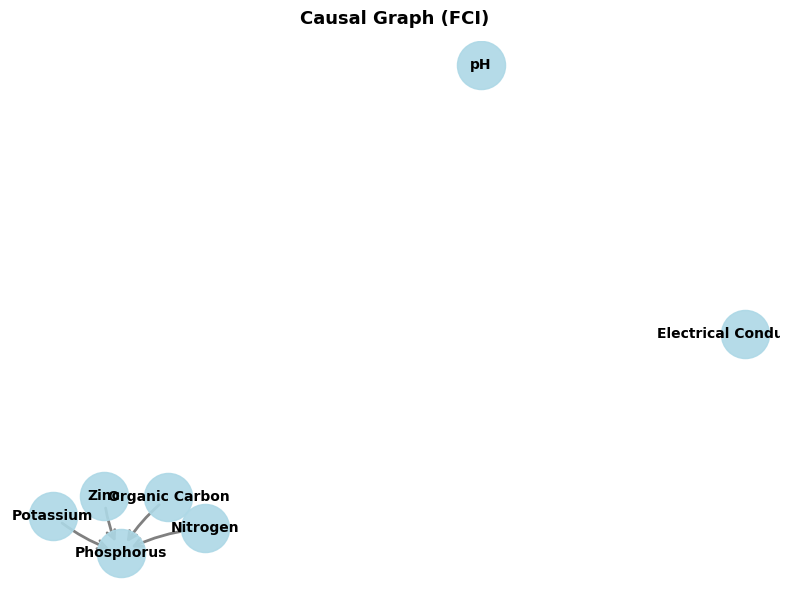

In [2]:
"""
CAUSAL SHAP on yield_preprocessed.npz
- Works with keys: X_train, X_test, y_train, y_test, feature_names
- Implements PC-based causal discovery, IDA-style causal effects, and Causal SHAP
- Saves outputs: causal graph PNG, comparison PNG, and CSV of attributions
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Tuple, Set
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from causallearn.search.ConstraintBased.FCI import fci
from sklearn.metrics import f1_score, accuracy_score
import networkx as nx

try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except:
    HAVE_XGB = False

HAVE_XGB=False


from causallearn.search.ConstraintBased.PC import pc

# Configuration
CONFIG = {
    'DATA_PATH': '../../datasets/soil_spi_preprocessed.npz',
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5, # Sample multiple DAGs from CPDAG
    'DISCOVERY_MODE': "fci"
}

np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])


# 1. Causal Discovery & Structure Learning

class CausalStructure:
    """Handles causal discovery and DAG sampling from CPDAG"""

    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names = None
        self.dags = []

    def discover(self, X: pd.DataFrame):
        """Run PC algorithm on features"""
        self.feature_names = list(X.columns)
        print(f"Running PC algorithm on {len(self.feature_names)} features...")

        pc_res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = pc_res.G.graph

        print(f"Causal discovery complete")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        """Convert CPDAG to networkx DiGraph"""
        G = nx.DiGraph()
        G.add_nodes_from(self.feature_names)

        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                # Directed edge i->j
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                # Undirected edge: add both directions
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    if i < j:  # Avoid double-adding
                        G.add_edge(self.feature_names[i], self.feature_names[j])
                        G.add_edge(self.feature_names[j], self.feature_names[i])

        return G

    def sample_dags(self, n_samples=5) -> List[nx.DiGraph]:
        """
        Sample multiple DAG orientations from CPDAG
        For undirected edges, randomly orient them
        """
        base_G = self.get_skeleton()
        dags = []

        # Find undirected edges
        undirected = []
        for i, u in enumerate(self.feature_names):
            for j, v in enumerate(self.feature_names):
                if i < j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((u, v))

        if len(undirected) == 0:
            # CPDAG is already fully directed
            print(f"  CPDAG is fully directed ({base_G.number_of_edges()} edges)")
            return [base_G]

        print(f"  Found {len(undirected)} undirected edges, sampling orientations...")

        # Sample orientations
        for _ in range(n_samples):
            G = nx.DiGraph()
            G.add_nodes_from(self.feature_names)

            # Add directed edges from CPDAG
            for i, u in enumerate(self.feature_names):
                for j, v in enumerate(self.feature_names):
                    if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(u, v)

            # Randomly orient undirected edges (ensuring acyclicity)
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)

                # Check for cycles and reverse if needed
                if not nx.is_directed_acyclic_graph(G):
                    G.remove_edge(u, v) if G.has_edge(u, v) else G.remove_edge(v, u)
                    G.add_edge(v, u) if not G.has_edge(v, u) else G.add_edge(u, v)

            dags.append(G)

        self.dags = dags
        return dags


# 2. Causal Mechanism Learning

class LinearMechanisms:
    """Learn linear structural equation models"""

    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag
        self.feature_names = feature_names
        self.mechanisms = {}
        self.topo_order = None

    def fit(self, X: pd.DataFrame):
        """Fit linear mechanisms for each variable"""
        # Get topological order
        try:
            self.topo_order = list(nx.topological_sort(self.dag))
        except:
            # Fallback if cycles exist
            self.topo_order = self._safe_topo_order()

        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))

            if not parents:
                # No parents: use marginal distribution
                self.mechanisms[var] = {
                    'parents': [],
                    'intercept': float(X[var].mean()),
                    'coef': None,
                    'sigma': float(X[var].std())
                }
            else:
                # Regress on parents
                lr = LinearRegression()
                lr.fit(X[parents].values, X[var].values)

                pred = lr.predict(X[parents].values)
                resid = X[var].values - pred

                self.mechanisms[var] = {
                    'parents': parents,
                    'intercept': float(lr.intercept_),
                    'coef': lr.coef_.astype(float),
                    'sigma': float(np.std(resid))
                }

        return self

    def _safe_topo_order(self) -> List[str]:
        """Fallback topological sort"""
        ordered = []
        remaining = set(self.feature_names)

        while remaining:
            # Find nodes with no remaining parents
            ready = [n for n in remaining
                    if all(p in ordered or p not in remaining
                           for p in self.dag.predecessors(n))]

            if not ready:
                # Force one with fewest remaining parents
                ready = [min(remaining,
                           key=lambda n: len([p for p in self.dag.predecessors(n)
                                            if p in remaining]))]

            for n in ready:
                ordered.append(n)
                remaining.remove(n)

        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series, rng) -> Dict:
        """
        Sample from interventional distribution do(X_S = x_S)
        """
        x_new = {}

        for var in self.topo_order:
            if var in S:
                x_new[var] = float(x_obs[var])
            else:
                # Sample from mechanism
                mech = self.mechanisms[var]

                if not mech['parents']:
                    # No parents: sample from marginal
                    mu, sigma = mech['intercept'], mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))
                else:
                    # Sample from conditional
                    parent_vals = np.array([x_new.get(p, x_obs[p])
                                           for p in mech['parents']])

                    mu = mech['intercept'] + parent_vals @ mech['coef']
                    sigma = mech['sigma']
                    if sigma < 1e-6:
                        x_new[var] = mu
                    else:
                        x_new[var] = float(rng.normal(mu, sigma))

        return x_new


# 3. Causal Effect Estimation (IDA-style)

class CausalEffects:
    """Estimate total causal effects using path analysis"""

    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        """
        Compute total causal effects for each feature on target
        Average over multiple DAG samples (IDA-style)
        """
        print("Computing causal effects (IDA-style)...")

        # Build augmented graphs with target
        aug_graphs = []

        for dag in self.dags:
            G = dag.copy()
            G.add_node('Y')

            # Add edges from features to Y with estimated weights
            for feat in self.feature_names:
                # Conditional regression: feat -> Y | other features
                other_feats = [f for f in self.feature_names if f != feat]
                if other_feats:
                    X_cond = np.column_stack([X[other_feats].values, X[feat].values])
                else:
                    X_cond = X[[feat]].values

                lr = LinearRegression()
                lr.fit(X_cond, y.values)
                weight = abs(lr.coef_[-1])

                if weight > 1e-6:
                    G.add_edge(feat, 'Y', weight=weight)

            # Add edge weights for feature->feature edges
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                if parents:
                    X_reg = np.column_stack([X[parents].values, X[u].values])
                else:
                    X_reg = X[[u]].values

                lr = LinearRegression()
                lr.fit(X_reg, X[v].values)
                weight = abs(lr.coef_[-1])
                G[u][v]['weight'] = weight

            aug_graphs.append(G)

        # Compute total effects (average over DAGs)
        total_effects = {feat: [] for feat in self.feature_names}

        for G in aug_graphs:
            for feat in self.feature_names:
                effect = 0.0

                # Sum over all paths feat -> Y
                try:
                    for path in nx.all_simple_paths(G, feat, 'Y', cutoff=10):
                        path_effect = 1.0
                        for i in range(len(path) - 1):
                            edge_data = G.get_edge_data(path[i], path[i+1])
                            if edge_data and 'weight' in edge_data:
                                path_effect *= edge_data['weight']
                        effect += path_effect
                except:
                    pass

                total_effects[feat].append(effect)

        # Average across DAGs
        self.effects = {feat: np.mean(effects)
                       for feat, effects in total_effects.items()}

        print(f"Causal effects computed (averaged over {len(self.dags)} DAGs)")
        return self.effects

    def get_gamma_weights(self) -> Dict[str, float]:
        """Compute gamma weights (normalized absolute effects)"""
        abs_effects = {k: abs(v) for k, v in self.effects.items()}
        total = sum(abs_effects.values()) + 1e-12

        return {k: v / total for k, v in abs_effects.items()}


# 4. Causal SHAP Implementation

class CausalSHAP:
    """Main Causal SHAP implementation"""

    def __init__(self, model, causal_structure: CausalStructure,
                 X_train: pd.DataFrame, y_train: pd.Series):
        self.model = model
        self.structure = causal_structure
        self.X_train = X_train
        self.y_train = y_train
        self.feature_names = list(X_train.columns)

        print("\\nLearning causal mechanisms...")
        # Learn mechanisms and effects
        self.dags = causal_structure.sample_dags(n_samples=CONFIG['N_DAGS'])
        self.mechanisms_list = [LinearMechanisms(dag, self.feature_names).fit(X_train)
                               for dag in self.dags]

        # Compute causal effects
        self.causal_effects = CausalEffects(self.dags, self.feature_names)
        self.causal_effects.compute_effects(X_train, y_train)
        self.gamma = self.causal_effects.get_gamma_weights()

        print(f"Learned {len(self.dags)} DAG orientations")

    def _causal_value_function(self, S: Set[str], x: pd.Series,
                               pred_class: int, M: int) -> float:
        """
        v_c(S) = E[f(X) | do(X_S = x_S)]
        Average over DAG samples and Monte Carlo samples
        """
        total = 0.0
        samples_per_dag = max(1, M // len(self.mechanisms_list))

        for mechanisms in self.mechanisms_list:
            for _ in range(samples_per_dag):
                x_sample = mechanisms.sample_intervention(S, x, rng)
                X_mat = pd.DataFrame([x_sample], columns=self.feature_names)

                prob = self.model.predict_proba(X_mat.values)[0][pred_class]
                total += prob

        actual_samples = samples_per_dag * len(self.mechanisms_list)
        return total / actual_samples

    def explain_instance(self, x: pd.Series, n_perms: int = None,
                        m_samples: int = None) -> pd.Series:
        """
        Compute Causal SHAP values for a single instance
        """
        if n_perms is None:
            n_perms = CONFIG['MAX_PERM']
        if m_samples is None:
            m_samples = CONFIG['M_RESAMPLES']

        # Get predicted class
        probs = self.model.predict_proba(pd.DataFrame([x],
                                         columns=self.feature_names).values)[0]
        pred_class = int(np.argmax(probs))

        # Permutation-based estimation
        phi = np.zeros(len(self.feature_names))

        for _ in range(n_perms):
            perm = rng.permutation(self.feature_names)
            S = set()
            v_prev = self._causal_value_function(S, x, pred_class, m_samples)

            for feat in perm:
                S_next = S | {feat}
                v_curr = self._causal_value_function(S_next, x, pred_class, m_samples)

                delta = v_curr - v_prev
                contrib = self.gamma[feat] * delta  # Causal weighting

                phi[self.feature_names.index(feat)] += contrib
                v_prev = v_curr
                S = S_next

        phi /= n_perms

        # Normalize for local accuracy
        f_x = probs[pred_class]
        v_empty = self._causal_value_function(set(), x, pred_class, m_samples)

        sum_phi = np.sum(phi)
        if abs(sum_phi) > 1e-12:
            phi = phi * ((f_x - v_empty) / sum_phi)

        return pd.Series(phi, index=self.feature_names, name='Causal_SHAP')

    def explain_global(self, X_test: pd.DataFrame, n_samples: int = None) -> pd.Series:
        """Global explanation: average over test instances"""
        if n_samples is None:
            n_samples = CONFIG['GLOBAL_K']

        n_samples = min(n_samples, len(X_test))
        indices = rng.choice(len(X_test), size=n_samples, replace=False)

        print(f"\\nComputing global Causal SHAP (averaging over {n_samples} instances)...")
        explanations = []
        for i, idx in enumerate(indices):
            if (i + 1) % 5 == 0:
                print(f"  Progress: {i+1}/{n_samples}")
            exp = self.explain_instance(X_test.iloc[idx],
                                       n_perms=max(10, CONFIG['MAX_PERM']//4))
            explanations.append(exp)

        print("ok Global Causal SHAP computed")
        return pd.concat(explanations, axis=1).mean(axis=1).rename('Causal_SHAP_Global')


# 5. Baseline Methods for Comparison (optional SHAP if installed)

def compute_baseline_shap(model, X_train, X_test):
    """Compute Kernel SHAP values if shap is installed"""
    try:
        import shap
        print("\\nComputing KERNEL SHAP baseline...")
        bg_size = min(100, len(X_train))
        bg = shap.kmeans(X_train.values, bg_size)
        explainer = shap.KernelExplainer(lambda x: model.predict_proba(x), bg)
        shap_values = explainer.shap_values(X_test.values, nsamples=100)

        # Average absolute values across classes
        if isinstance(shap_values, list):
            global_imp = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values], axis=0)
        else:
            global_imp = np.abs(shap_values).mean(axis=0)
        print("ok KERNEL SHAP computed")
        return pd.Series(global_imp, index=X_test.columns, name='SHAP_kernel')
    except Exception as e:
        print(f"Warning: SHAP computation skipped/failed: {e}")
        return None


def compute_feature_importance(model, feature_names):
    """Compute model's native feature importance"""
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        return pd.Series(imp, index=feature_names, name='Model_Importance')
    return None


# 6. Visualization (pure matplotlib, no seaborn)

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1]))
    ax.set_yticks(np.arange(data.shape[0]))
    ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    ax.set_title(title)


def plot_comparison(df_comp: pd.DataFrame, title: str = "Feature Attribution Comparison"):
    """Visualize comparison of different methods (matplotlib only)"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Bar plot
    axes[0, 0].bar(np.arange(df_comp.shape[0]), df_comp.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\\n(Bar Chart: first method)', fontsize=12, fontweight='bold')
    axes[0, 0].set_ylabel('Attribution Score', fontsize=11)
    axes[0, 0].set_xlabel('Feature', fontsize=11)
    axes[0, 0].set_xticks(np.arange(df_comp.shape[0]))
    axes[0, 0].set_xticklabels(df_comp.index, rotation=45, ha='right')
    axes[0, 0].grid(axis='y', alpha=0.3)

    # Heatmap
    annotate_heatmap(axes[0, 1], df_comp.T, 'Attribution Heatmap', 'Score')

    # Normalized comparison
    df_norm = df_comp.div(df_comp.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col], width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized Attribution (by method max)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Normalized Score', fontsize=11)
    axes[1, 0].set_xlabel('Feature', fontsize=11)
    axes[1, 0].set_xticks(np.arange(df_norm.shape[0]))
    axes[1, 0].set_xticklabels(df_norm.index, rotation=45, ha='right')
    axes[1, 0].legend(loc='best', fontsize=9)
    axes[1, 0].grid(axis='y', alpha=0.3)

    # Rank comparison heatmap
    ranks = df_comp.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Feature Importance Ranking', 'Rank')

    fig.tight_layout()
    return fig


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph"):
    """Visualize the causal graph"""
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)

    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15,
                           arrowstyle='->', width=2, connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off')
    plt.tight_layout()
    return plt.gcf()


def build_true_causal_structure(X_train_scaled: pd.DataFrame) -> CausalStructure:
    """
    Build CausalStructure using the TRUE DAG from the soil DGP:
        Organic Carbon -> pH -> Zinc
    No other directed edges among features.
    """
    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.feature_names = list(X_train_scaled.columns)

    n = len(causal_structure.feature_names)
    cpdag = np.zeros((n, n), dtype=int)

    name_to_idx = {name: i for i, name in enumerate(causal_structure.feature_names)}

    def add_directed(u: str, v: str):
        """
        Encode a directed edge u -> v into cpdag:
            cpdag[u,v] = -1, cpdag[v,u] = 1
        This matches causallearn's CPDAG convention used in CausalStructure.get_skeleton().
        """
        i, j = name_to_idx[u], name_to_idx[v]
        cpdag[i, j] = -1
        cpdag[j, i] = 1

    # Organic Carbon -> pH -> Zinc
    add_directed('Organic Carbon', 'pH')
    add_directed('pH', 'Zinc')

    causal_structure.cpdag = cpdag
    return causal_structure


def build_fci_structure(X_train_scaled: pd.DataFrame) -> CausalStructure:
    """
    Run FCI to detect causal relations under latent confounding.
    Converts the PAG edges into a CPDAG-like structure usable by the rest of the pipeline.
    """
    print("Running FCI (accounts for latent confounders)...")

    nodes = list(X_train_scaled.columns)
    n = len(nodes)
    causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
    causal_structure.feature_names = nodes

    pag_obj, _ = fci(X_train_scaled.values)
    pag = pag_obj.graph   # adjacency matrix (n × n)

    cpdag = np.zeros((n, n), dtype=int)

    # Interpret PAG edges for CPDAG construction
    for i, u in enumerate(nodes):
        for j, v in enumerate(nodes):
            if i == j:
                continue

            mark = pag[i, j]

            # Directed edge u -> v
            if mark == -1 and pag[j, i] == 1:
                cpdag[i, j] = -1
                cpdag[j, i] = 1

            # Latent confounder: u ↔ v
            elif mark == 2 and pag[j, i] == 2:
                cpdag[i, j] = cpdag[j, i] = -1   # treat like undirected

            # Partial edges (o->, <-o, o-o): treat as undirected
            elif mark == -1 and pag[j, i] == -1:
                cpdag[i, j] = cpdag[j, i] = -1

    causal_structure.cpdag = cpdag
    return causal_structure


# 7. Main Execution

def main():
    """Run complete Causal SHAP analysis on NPZ dataset"""

    print("\\n" + "="*70)
    print("CAUSAL SHAP on NPZ Dataset")
    print("="*70 + "\\n")

    # Load data
    print("Loading NPZ dataset...")
    try:
        data = np.load(CONFIG['DATA_PATH'], allow_pickle=True)
        keys = list(data.keys())
        print(f"NPZ loaded with keys: {keys}")
    except FileNotFoundError:
        print(f"ERROR: Could not find '{CONFIG['DATA_PATH']}'")
        print("Please ensure the file is in the current directory.")
        return

    required_keys = {'X_train', 'X_test', 'y_train', 'y_test', 'feature_names'}
    if not required_keys.issubset(set(keys)):
        print("ERROR: NPZ must contain X_train, X_test, y_train, y_test, feature_names.")
        return

    # Extract
    X_train = pd.DataFrame(data['X_train'], columns=list(data['feature_names']))
    X_test  = pd.DataFrame(data['X_test'],  columns=list(data['feature_names']))
    y_train = pd.Series(data['y_train'].astype(int))
    y_test  = pd.Series(data['y_test'].astype(int))

    print(f"Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}")
    print(f"Features: {', '.join(X_train.columns)}")
    n_classes = len(np.unique(y_train))
    print(f"Target classes: {n_classes}")

    # Scale features using training stats
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

    # Train model
    print("\\n" + "="*70)
    print("Training Model")
    print("="*70)

    if HAVE_XGB:
        model = XGBClassifier(
            n_estimators=160,
            max_depth=5,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=CONFIG['RANDOM_SEED'],
            verbosity=0,
            objective="multi:softprob",
            num_class=n_classes,
        )
        print("Using XGBoost classifier")
    else:
        model = RandomForestClassifier(
            n_estimators=160,
            max_depth=6,
            random_state=CONFIG['RANDOM_SEED']
        )
        print("Using Random Forest classifier")

    model.fit(X_train_scaled.values, y_train.values)

    y_pred = model.predict(X_test_scaled.values)
    f1 = f1_score(y_test, y_pred, average='macro')
    acc = accuracy_score(y_test, y_pred)

    print(f"Model trained")
    print(f"  Test Accuracy: {acc:.4f}")
    print(f"  Test Macro F1: {f1:.4f}")

    # Causal Discovery
# Step 1 - Causal Discovery (TRUE / PC / FCI)
    print("\n" + "="*70)
    mode = CONFIG['DISCOVERY_MODE'].lower()

    if mode == "true":
        print("Step 1: Using TRUE Causal Graph (from generator)")
        causal_structure = build_true_causal_structure(X_train_scaled)

    elif mode == "pc":
        print("Step 1: PC Algorithm (assumes no latent confounders)")
        causal_structure = CausalStructure(alpha=CONFIG['ALPHA_PC'])
        causal_structure.discover(X_train_scaled)

    elif mode == "fci":
        print("Step 1: FCI Algorithm (handles latent confounders)")
        causal_structure = build_fci_structure(X_train_scaled)

    else:
        raise ValueError("CONFIG['DISCOVERY_MODE'] must be one of: true, pc, fci")

    # Visualize graph
    G = causal_structure.get_skeleton()
    print(f"\nGraph ({mode}) has {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.")

    fig_graph = plot_causal_graph(G, f"Causal Graph ({mode.upper()})")
    fig_graph.savefig(f"causal_graph_{mode}.png", dpi=150, bbox_inches='tight')
    print(f"Saved causal graph to causal_graph_{mode}.png")


    # Causal SHAP
    print("\\n" + "="*70)
    print("Step 2: Computing Causal SHAP")
    print("="*70)

    causal_shap = CausalSHAP(model, causal_structure, X_train_scaled, y_train)

    # Show causal effects
    print("\\nTotal Causal Effects (W_i):")
    print("-" * 40)
    for feat in X_train.columns:
        effect = causal_shap.causal_effects.effects[feat]
        gamma = causal_shap.gamma[feat]
        print(f"  {feat:15s}: W={effect:8.4f}  γ={gamma:.4f}")

    # Global explanation
    global_causal_shap = causal_shap.explain_global(X_test_scaled, n_samples=CONFIG['GLOBAL_K'])

    # Baseline methods (optional)
    print("\\n" + "="*70)
    print("Step 3: Computing Baseline Methods")
    print("="*70)
    baseline_shap = compute_baseline_shap(model, X_train_scaled, X_test_scaled)
    model_imp = compute_feature_importance(model, list(X_train.columns))

    # Comparison
    print("\\n" + "="*70)
    print("Step 4: Results Comparison")
    print("="*70)

    attributions = {
        'Causal_SHAP': global_causal_shap,
    }

    if baseline_shap is not None:
        attributions['Kernel_SHAP'] = baseline_shap

    if model_imp is not None:
        attributions['Model_Importance'] = model_imp

    df_comparison = pd.DataFrame(attributions)
    df_comparison.to_csv('attribution_scores_yield.csv', index=True)

    print("\\n" + "="*70)
    print("Attribution Scores:")
    print("="*70)
    print(df_comparison.round(6).to_string())
    print("\\nSaved CSV -> attribution_scores_yield.csv")

    # Correlation analysis
    if len(attributions) > 1:
        print("\\n" + "="*70)
        print("Correlation between methods:")
        print("="*70)
        corr_matrix = df_comparison.corr()
        print(corr_matrix.round(4).to_string())

    # Visualization
    fig = plot_comparison(df_comparison,
                         title="Feature Attribution Comparison (Yield NPZ)")
    fig.savefig('attribution_comparison_yield.png', dpi=150, bbox_inches='tight')
    print("\\nok Comparison plot saved to 'attribution_comparison_yield.png'")

    try:
        plt.show()
    except Exception:
        pass

if __name__ == "__main__":
    main()